# Business and Restaurant Data Analysis
This notebook demonstrates an exploratory data analysis of a restaurant dataset. We load the dataset, analyze business types, evaluate chain vs. non-chain establishments, inspect seating capacities, and categorize menu sizes for highly-rated locations.

In [ ]:
# Import the pandas library for data manipulation and analysis
import pandas as pd
# Import the pyplot module from matplotlib for data visualization
from matplotlib import pyplot as plt

# Define the raw GitHub URL pointing directly to the CSV dataset file
url = "https://raw.githubusercontent.com/AlaKargar/Data-Science/main/dataset.csv"
# Use pandas to read the CSV file from the web URL and load it into a DataFrame
df = pd.read_csv(url)
# Use the display function to render the first five rows of the DataFrame in the output
display(df.head())

,name,chain,type,seat,location,menu items,rate,telephone
0,shila,True,Restaurant,50,1,59,4.7,88862491
1,land,True,Pizza,40,1,45,4.3,88215242
2,naam,False,Café,30,0,20,4.0,88922948
3,noon,True,Café,15,1,15,5.0,38449276
4,shabdiz,True,Restaurant,100,1,42,4.9,38666666


In [ ]:
# Drop the 'name' column permanently from the DataFrame along the column axis (axis=1)
df.drop(['name'] , axis=1, inplace=True)
# Retrieve and display the 'chain' column values from the DataFrame
df['chain']
# Display the entire updated DataFrame with the 'name' column removed
df

,chain,type,seat,location,menu items,rate,telephone
0,True,Restaurant,50,1,59,4.7,88862491
1,True,Pizza,40,1,45,4.3,88215242
2,False,Café,30,0,20,4.0,88922948
3,True,Café,15,1,15,5.0,38449276
4,True,Restaurant,100,1,42,4.9,38666666
5,True,Pastry,0,1,8,4.0,3724 1053
6,False,Bakery,0,0,3,4.0,32259269
7,False,Bakery,0,0,10,4.5,3876 2200
8,NaN,Fast Food,20,1,40,4.7,3603 1616


In [ ]:
# Print a concise summary of the DataFrame, showing data types, non-null counts, and memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   chain       8 non-null      object 
 1   type        9 non-null      object 
 2   seat        9 non-null      int64  
 3   location    9 non-null      int64  
 4   menu items  9 non-null      int64  
 5   rate        9 non-null      float64
 6   telephone   9 non-null      object 
dtypes: float64(1), int64(3), object(3)
memory usage: 636.0+ bytes


In [ ]:
# Filter and display only the rows where the values in the 'chain' column are null
df[df['chain'].isnull()]

,chain,type,seat,location,menu items,rate,telephone
8,NaN,Fast Food,20,1,40,4.7,3603 1616


In [ ]:
# Find and return an array of all unique elements found in the 'chain' column
df['chain'].unique()

array([True, False, nan], dtype=object)

In [ ]:
# Count the occurrences of each unique non-null value in the 'chain' column
df['chain'].value_counts()

,count
chain,
True,5
False,3


In [ ]:
# Calculate and return the total number of missing (NaN) values in the 'chain' column
df['chain'].isnull().sum()

np.int64(1)

In [ ]:
# Remove duplicate rows in-place so that only unique records remain in the DataFrame
df.drop_duplicates(inplace=True)

In [ ]:
# Count how many times each type of business appears and save the series to count_type
count_type = df['type'].value_counts()
# Display the counts of each unique business type
count_type

,count
type,
Restaurant,2
Café,2
Bakery,2
Pizza,1
Pastry,1
Fast Food,1


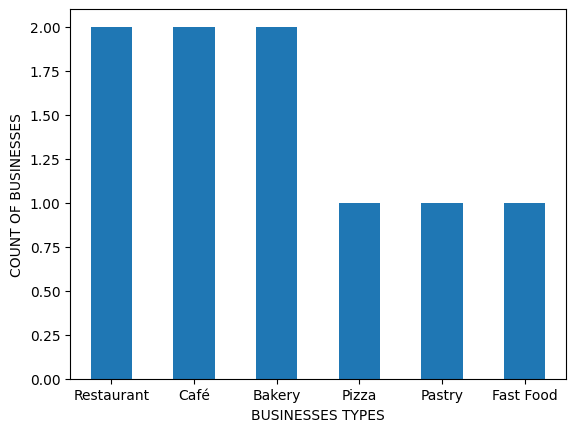

In [ ]:
# Generate a bar chart of the business type frequencies with labels kept horizontal (rot=0)
count_type.plot(kind='bar', rot=0)
# Set the label for the horizontal axis of the bar chart
plt.xlabel('BUSINESSES TYPES')
# Set the label for the vertical axis of the bar chart
plt.ylabel('COUNT OF BUSINESSES')
# Render and display the generated plot on the screen
plt.show()

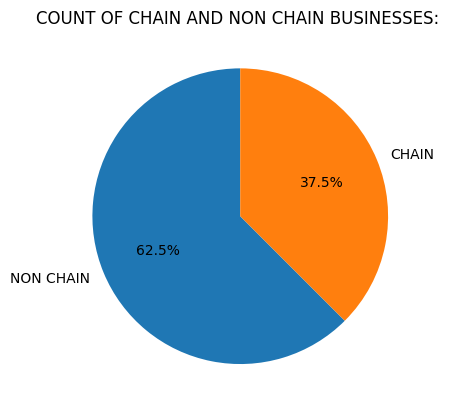

In [ ]:
# Extract the counts of chain and non-chain businesses to use for the pie chart slices
protation_chain = df['chain'].value_counts()
# Create a figure and axis object with a clean white background
fig, ax = plt.subplots(facecolor='white')
# Plot a pie chart with percentage values, category labels, and set the starting rotation angle
ax.pie(protation_chain, labels=['NON CHAIN', 'CHAIN'], autopct='%1.1f%%', startangle=90)
# Define the title text to be displayed above the pie chart
ax.set_title('COUNT OF CHAIN AND NON CHAIN BUSINESSES: ')
# Render and display the final pie chart layout
plt.show()

In [ ]:
# Group the data by business type and chain status, count occurrences, and sort them ascendingly
chains = df.groupby(['type', 'chain'])['chain'].count().sort_values()
# Display the resulting grouped series counts
chains

type        chain
Café        False    1
            True     1
Pastry      True     1
Pizza       True     1
Bakery      False    2
Restaurant  True     2
Name: chain, dtype: int64

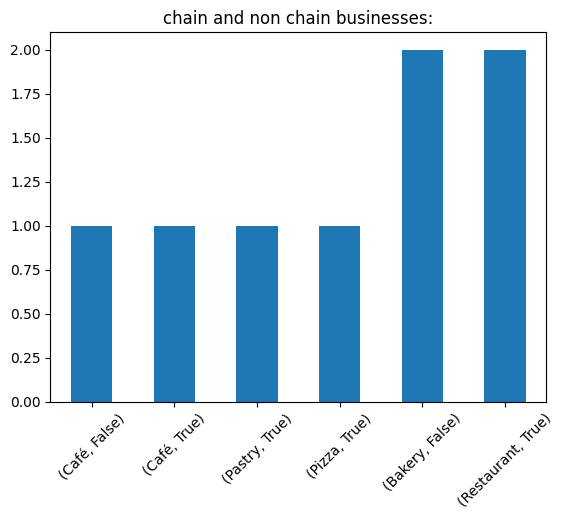

In [ ]:
# Generate a bar chart representing the grouped chain/non-chain business types with labels rotated
chains.plot(kind='bar', rot=45)
# Clear the default x-axis label to improve the visual presentation
plt.xlabel("")
# Define the title of the bar chart
plt.title("chain and non chain businesses:")
# Show the generated grouped bar chart
plt.show()

In [ ]:
# Filter the DataFrame to extract only the rows representing chain businesses
is_chain = df[df['chain'] == True]
# Display the filtered DataFrame containing only chain establishments
is_chain

,chain,type,seat,location,menu items,rate,telephone
0,True,Restaurant,50,1,59,4.7,88862491
1,True,Pizza,40,1,45,4.3,88215242
3,True,Café,15,1,15,5.0,38449276
4,True,Restaurant,100,1,42,4.9,38666666
5,True,Pastry,0,1,8,4.0,3724 1053


In [ ]:
# Compute and print the summary statistics (mean, min, max, std, percentiles) for seating capacity
print(is_chain['seat'].describe())

count      5.000000
mean      41.000000
std       38.470768
min        0.000000
25%       15.000000
50%       40.000000
75%       50.000000
max      100.000000
Name: seat, dtype: float64


In [ ]:
# Filter rows where the business rating is greater than 3.5 and assign to rate variable
rate=df[df['rate']> 3.5]
# Count and display the distribution of business types within this highly-rated group
rate['type'].value_counts()

,count
type,
Restaurant,2
Café,2
Bakery,2
Pizza,1
Pastry,1
Fast Food,1


In [ ]:
# Define a function to categorize a number of items as 'few' (less than 14) or 'many' (14 or more)
def f(x):
    # Check if the number of items is less than the threshold of 14
    if x < 14:
        # Return the label 'few' if the condition is met
        return 'few'
    else:
        # Otherwise, return the label 'many'
        return 'many'

In [ ]:
# Apply the categorization function to 'menu items' column and store results in a new column 'menu'
rate['menu'] = rate['menu items'].apply(f)
# Display the updated rate DataFrame containing the new categorical 'menu' column
rate

,chain,type,seat,location,menu items,rate,telephone,menu
0,True,Restaurant,50,1,59,4.7,88862491,many
1,True,Pizza,40,1,45,4.3,88215242,many
2,False,Café,30,0,20,4.0,88922948,many
3,True,Café,15,1,15,5.0,38449276,many
4,True,Restaurant,100,1,42,4.9,38666666,many
5,True,Pastry,0,1,8,4.0,3724 1053,few
6,False,Bakery,0,0,3,4.0,32259269,few
7,False,Bakery,0,0,10,4.5,3876 2200,few
8,NaN,Fast Food,20,1,40,4.7,3603 1616,many


In [ ]:
# Obtain the total counts of businesses labeled with 'many' and 'few' menu items
menu_daste = rate['menu'].value_counts()
# Print the frequency counts of the menu item categories
menu_daste

,count
menu,
many,6
few,3


Text(0.5, 1.0, 'COUNT OF MENU ITEMS OF BUSINESSES THEY HAVE RATE > 3.5')

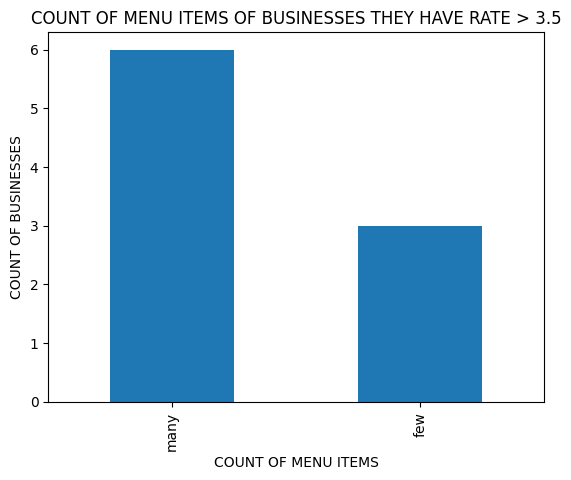

In [ ]:
# Plot a bar chart showing the frequency of menu sizes for highly-rated businesses
menu_daste.plot(kind='bar')
# Label the horizontal axis indicating the categorical menu size classifications
plt.xlabel("COUNT OF MENU ITEMS")
# Label the vertical axis showing the count of corresponding businesses
plt.ylabel("COUNT OF BUSINESSES")
# Set the descriptive title for the bar plot
plt.title("COUNT OF MENU ITEMS OF BUSINESSES THEY HAVE RATE > 3.5")
# Display the rendered visualization
plt.show()